This notebook shows how to use the easiest interface in HiGP for regression problems.

We use a simple example to show the basic usage of HiGP. In this example, we train a RBF (Gaussian) kernel GP for a one-dimensional function. We will be modeling the function

```math
y = 0.2 \sin(3 \pi x) \exp(4x) + \epsilon, \ 
\epsilon \sim \mathcal{N}(0, 0.09)
```

The regression can be calculated by `higp_py.ezgpr_torch()`. By default, it is in single precision.

In this example, we use the RBF (Gaussian) kernel function in the form
$$
\mathcal{K}(x,y)=f^2 \exp\left(\frac{-\|x - y\|_2^2}{2 l^2}\right).
$$

As we hope to make the actual parameters in $(0,\infty)$, we train our parameters in $\mathbb{R}$ and apply the softplus transformation to get the actual parameters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import torch
import higp
%matplotlib inline

In [2]:
# Generate the dataset
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
n_train = 200
n_test  = 1000
train_x = np.linspace(0, 1, n_train)
train_y = 0.2 * np.sin(3 * math.pi * train_x) * np.exp(4 * train_x) 
train_y += np.random.randn(train_x.size) * math.sqrt(0.09)
test_x  = np.sort(np.random.rand(n_test))
test_y  = 0.2 * np.sin(3 * math.pi * test_x) * np.exp(4 * test_x)
test_y += np.random.randn(test_x.size) * math.sqrt(0.09)

We first visualize the training set and testing set.

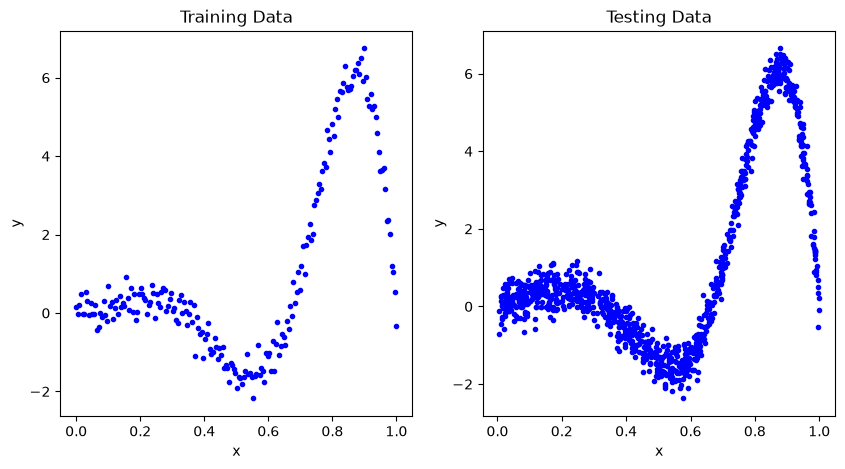

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].plot(train_x, train_y, 'b.')
axs[0].set_title('Training Data')
axs[0].set_xlabel('x')
axs[0].set_ylabel('y')
axs[1].plot(test_x, test_y, 'b.')
axs[1].set_title('Testing Data')
axs[1].set_xlabel('x')
axs[1].set_ylabel('y')
plt.show()
plt.close(fig)

Next, we directly call the simplest interface.

We use a learning rate 0.1 by setting `adam_lr = 0.1`.

In [4]:
pred = higp.ezgpr_torch(train_x, train_y, test_x, test_y, adam_lr=0.1, adam_maxits=100)

Read 200 training / 1000 test data points
Data dimension: 1
Set random seed to 42
Setting up GPR problem with 200 samples and 1 features
Init gpr problem done
Creating GPR problem
Data type: float
Kernel type: Gaussian
Transform type: softplus
Using preconditioned GP, kernel matrix form: dense / fall back to on-the-fly
AFN preconditioner parameters: rank 50, lfil 0
LanQ parameters: niter 10, nvec 10
Iteration (max 100), Elapsed time (sec), Loss, Hyperparameters (l, s, f, before nnt)


/home/chab/Hmat dossier code/hmat_env/lib/python3.14/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12090). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


1, 0.42, 2.77837, -0.100, 0.100, 0.100
2, 0.76, 2.57451, -0.200, 0.199, 0.199
3, 1.15, 2.39972, -0.299, 0.296, 0.297
4, 1.46, 2.25158, -0.397, 0.391, 0.393
5, 1.76, 2.12600, -0.495, 0.484, 0.486
6, 1.98, 2.01785, -0.592, 0.572, 0.577
7, 2.30, 1.92152, -0.689, 0.657, 0.664
8, 2.62, 1.83180, -0.786, 0.736, 0.749
9, 2.87, 1.74478, -0.883, 0.808, 0.832
10, 3.15, 1.65900, -0.982, 0.873, 0.913
11, 3.37, 1.57589, -1.081, 0.930, 0.993
12, 3.65, 1.49846, -1.180, 0.977, 1.072
13, 3.89, 1.42924, -1.279, 1.014, 1.148
14, 4.14, 1.36997, -1.376, 1.041, 1.223
15, 4.36, 1.32210, -1.471, 1.059, 1.295
16, 4.63, 1.28559, -1.562, 1.068, 1.364
17, 4.97, 1.25830, -1.649, 1.069, 1.430
18, 5.22, 1.23750, -1.731, 1.063, 1.492
19, 5.47, 1.22102, -1.808, 1.049, 1.551
20, 5.73, 1.20741, -1.880, 1.029, 1.606
21, 6.01, 1.19568, -1.946, 1.004, 1.658
22, 6.27, 1.18507, -2.008, 0.973, 1.705
23, 6.51, 1.17500, -2.064, 0.937, 1.750
24, 6.92, 1.16506, -2.115, 0.897, 1.791
25, 7.22, 1.15491, -2.161, 0.854, 1.829
26, 7.60,

Visualize the prediction results.

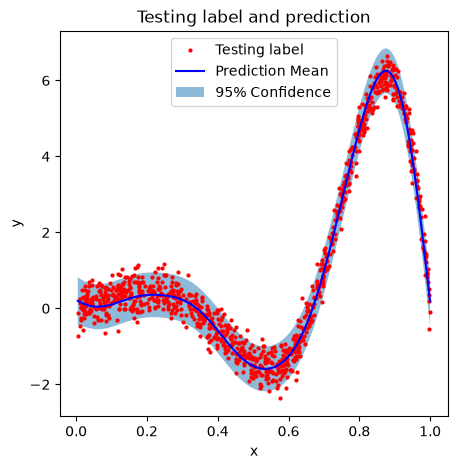

In [5]:
plt.figure(figsize=(5, 5))
plt.plot(test_x, test_y, 'ro', markersize=2)
pred_y = pred.prediction_mean
std_y = pred.prediction_stddev
plt.plot(test_x, pred_y, 'b-')
plt.fill_between(test_x, pred_y - 1.96 * std_y, pred_y + 1.96 * std_y, alpha=0.5)
plt.title('Testing label and prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(['Testing label', 'Prediction Mean', '95% Confidence'], loc='upper center')
plt.show()
plt.close(fig)